In [ ]:
# 32. Develop an Autoencoder-based anomaly detection model to identify 
# abnormal ECG signal patterns using an ECG dataset. Perform the 
# following steps: 
# a. Import Libraries: Import the required Python libraries such as NumPy, 
# Pandas, Matplotlib and TensorFlow/Keras. 
# b. Dataset Access: Load the ECG dataset, separate normal and abnormal 
# ECG records, and perform necessary preprocessing and normalization. 
# c. Encoder Implementation: Design an encoder network using Dense 
# layers to convert the input ECG signals into a compressed latent 
# representation. 
# d. Decoder Implementation: Design a decoder network to reconstruct the 
# original ECG signals from the compressed latent representation. 
# e. Model Compilation: Compile the Autoencoder using the Adam 
# optimizer, Mean Squared Error (MSE) loss function and suitable 
# evaluation metrics. 
# f. Model Training: Train the Autoencoder primarily using normal ECG 
# signals so that it learns to reconstruct normal patterns. 
# g. Anomaly Detection: Calculate reconstruction errors for test ECG 
# signals and identify abnormal signals using a suitable threshold. 
# h. Output: Display original and reconstructed ECG signals, reconstruction 
# errors and identify normal and abnormal ECG patterns. 

In [1]:
# Step 1: Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

In [2]:
# Step 2: Load ECG dataset
data = pd.read_csv('ecg.csv', header=None)

# Separate ECG signals and labels
X = data.iloc[:, :-1].values
y = data.iloc[:, -1].values

# Display dataset details
print("Dataset Shape:", data.shape)
print("Normal Records:", np.sum(y == 1))
print("Abnormal Records:", np.sum(y == 0))

Dataset Shape: (4998, 141)
Normal Records: 2919
Abnormal Records: 2079


In [3]:
# Step 3: Separate normal and abnormal ECG signals
normal = X[y == 1]
abnormal = X[y == 0]

# Split normal data into training and testing
X_train, X_normal_test = train_test_split(
    normal, test_size=0.2, random_state=42
)

# Combine normal and abnormal records for testing
X_test = np.concatenate([X_normal_test, abnormal])

y_test = np.concatenate([
    np.ones(len(X_normal_test)),
    np.zeros(len(abnormal))
])

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (2335, 140)
Testing Shape: (2663, 140)


In [4]:
# Step 4: Normalize ECG signals
scaler = MinMaxScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Data Normalized Successfully!")

Data Normalized Successfully!


In [5]:
# --------------------------------
# ENCODER AND DECODER
# --------------------------------

# Step 5: Build Autoencoder
model = tf.keras.Sequential([
    # Encoder
    tf.keras.layers.Input(shape=(140,)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(8, activation='relu'),

    # Decoder
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(140, activation='sigmoid')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │           9,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 8)                   │             264 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 32)                  │             288 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 64)                  │           2,112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 140)                 │           9,100 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 22,868 (89.33 KB)

 Trainable params: 22,868 (89.33 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Step 6: Compile the model
model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

In [7]:
# Step 7: Train using only normal ECG signals
history = model.fit(
    X_train,
    X_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

print("Model Training Completed!")

Epoch 1/20
59/59 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - loss: 0.0141 - mae: 0.0877 - val_loss: 0.0087 - val_mae: 0.0655
Epoch 2/20
59/59 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0075 - mae: 0.0598 - val_loss: 0.0061 - val_mae: 0.0541
Epoch 3/20
59/59 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0054 - mae: 0.0501 - val_loss: 0.0048 - val_mae: 0.0479
Epoch 4/20
59/59 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0047 - mae: 0.0466 - val_loss: 0.0045 - val_mae: 0.0462
Epoch 5/20
59/59 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0044 - mae: 0.0450 - val_loss: 0.0042 - val_mae: 0.0445
Epoch 6/20
59/59 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0041 - mae: 0.0430 - val_loss: 0.0039 - val_mae: 0.0429
Epoch 7/20
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0037 - mae: 0.0413 - val_loss: 0.0038 - val_mae: 0.0420
Epoch 8/20
59/59 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0036 - mae: 0.0405 - val_loss: 0.0037 - val_mae: 0.0415
Epoch 9/20
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0035 - mae:

In [8]:
# Step 8: Reconstruct test ECG signals
reconstructed = model.predict(X_test)

# Calculate reconstruction errors
errors = np.mean(np.square(X_test - reconstructed), axis=1)

# Set anomaly threshold using 95th percentile of training errors
train_reconstructed = model.predict(X_train)
train_errors = np.mean(np.square(X_train - train_reconstructed), axis=1)

threshold = np.percentile(train_errors, 95)

# Identify normal and abnormal signals
predictions = np.where(errors > threshold, 0, 1)

print("Anomaly Threshold:", threshold)
print("Normal Predictions:", np.sum(predictions == 1))
print("Abnormal Predictions:", np.sum(predictions == 0))

84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Anomaly Threshold: 0.00768491389232124
Normal Predictions: 568
Abnormal Predictions: 2095


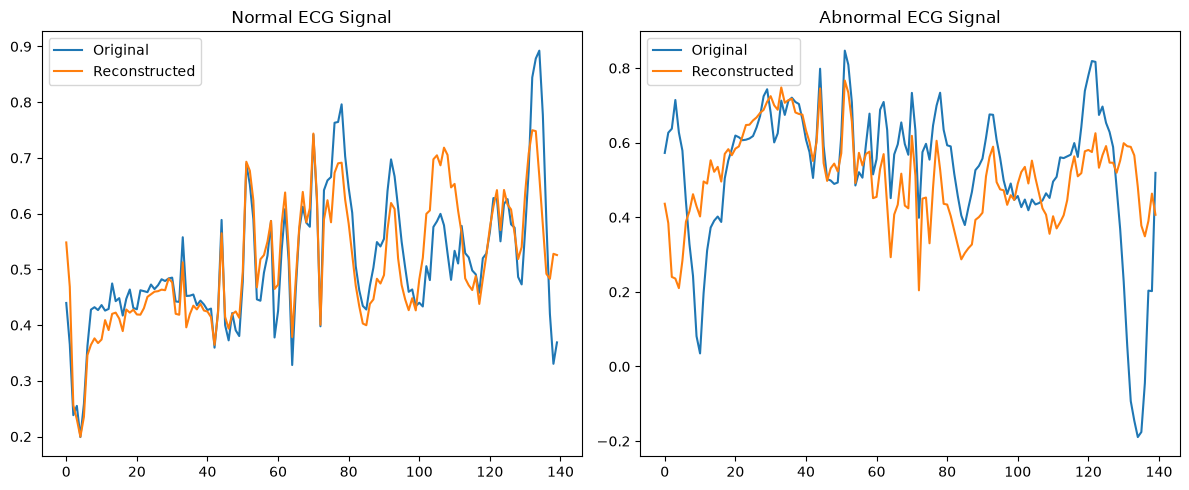

In [9]:
# Step 9: Display original and reconstructed ECG signals

plt.figure(figsize=(12, 5))

# Display normal ECG signal
plt.subplot(1, 2, 1)
plt.plot(X_test[0], label='Original')
plt.plot(reconstructed[0], label='Reconstructed')
plt.title("Normal ECG Signal")
plt.legend()

# Display abnormal ECG signal
abnormal_index = len(X_normal_test)

plt.subplot(1, 2, 2)
plt.plot(X_test[abnormal_index], label='Original')
plt.plot(reconstructed[abnormal_index], label='Reconstructed')
plt.title("Abnormal ECG Signal")
plt.legend()

plt.tight_layout()
plt.show()

In [10]:
# Step 10: Display reconstruction errors and predictions

for i in range(10):
    if predictions[i] == 1:
        result = "Normal"
    else:
        result = "Abnormal"

    print("Record:", i+1,
          "Error:", errors[i],
          "Prediction:", result)

Record: 1 Error: 0.004158110541235661 Prediction: Normal
Record: 2 Error: 0.0029342245512504013 Prediction: Normal
Record: 3 Error: 0.0022057496772936286 Prediction: Normal
Record: 4 Error: 0.003986274489717111 Prediction: Normal
Record: 5 Error: 0.0033052803952870755 Prediction: Normal
Record: 6 Error: 0.005589112595796369 Prediction: Normal
Record: 7 Error: 0.0017140732137233862 Prediction: Normal
Record: 8 Error: 0.0030788630377061926 Prediction: Normal
Record: 9 Error: 0.0013799517872959705 Prediction: Normal
Record: 10 Error: 0.001305104852915863 Prediction: Normal


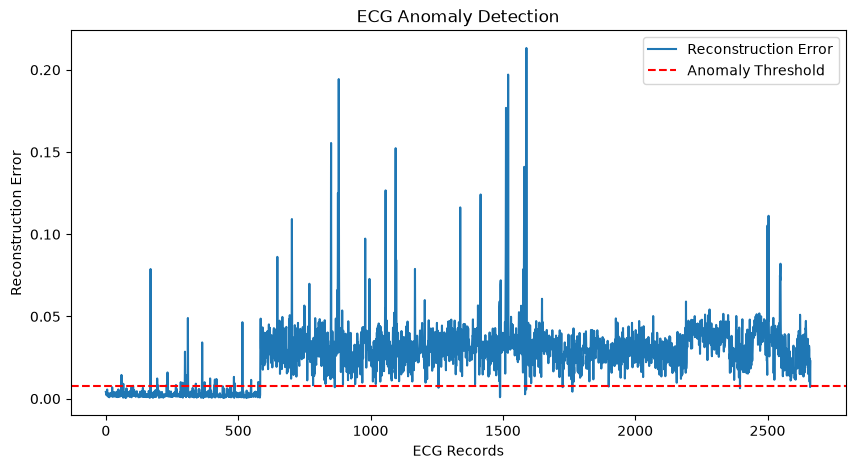

In [11]:
# Step 11: Plot reconstruction errors
plt.figure(figsize=(10, 5))

plt.plot(errors, label='Reconstruction Error')
plt.axhline(y=threshold, color='red', linestyle='--',
            label='Anomaly Threshold')

plt.title("ECG Anomaly Detection")
plt.xlabel("ECG Records")
plt.ylabel("Reconstruction Error")
plt.legend()
plt.show()